# FASTA2GO - Etapa 2: análise exploratória

Investiga a base construída na Etapa 1 (`db/fasta2go.duckdb`) e o espaço de rótulos de
função molecular usado na Etapa 3: **41 termos do GO Slim** (`goslim_generic` de função
molecular + `GO:0005488 binding`, raiz `GO:0003674` excluída), com propagação de todos os
ancestrais `is_a`/`part_of`.

**Como executar.** Com o kernel do `.venv`:

```bash
uv sync                                       # dependências (seaborn está no grupo dev)
uv run python etapa1/main.py                  # constrói db/fasta2go.duckdb, se ainda não existir
uv run python etapa1/build_go_slim_labels.py  # gera exports/go_slim/protein_labels.csv
```

**Escopo e limites.** Nada aqui altera dados: o banco é aberto em modo **somente leitura**
e nenhum arquivo é gravado. Esta etapa não treina modelos, não remove atributos e não usa
conjunto de teste — apenas mede a base e documenta candidatos para a Etapa 3. A amostra é de
**2.000 proteínas** (`limit` em `etapa1/fasta2go.config`), então as prevalências valem para esta
amostra, não para o Swiss-Prot completo.


In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# A raiz do projeto é localizada por marcador: o kernel abre com cwd na pasta do notebook.
ROOT = next(p for p in Path.cwd().resolve().parents if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

from fasta2go import db, features, pipeline  # noqa: E402

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.width", 170, "display.max_columns", 60)

DATABASE = ROOT / "db" / "fasta2go.duckdb"
LABELS = ROOT / "exports" / "go_slim" / "protein_labels.csv"
VOCABULARY = ROOT / "data" / "go_slim" / "vocabulary_mf.csv"

assert DATABASE.exists(), f"base ausente: rode `uv run python etapa1/main.py` ({DATABASE})"
assert LABELS.exists(), (
    f"rótulos ausentes: rode `uv run python etapa1/build_go_slim_labels.py` ({LABELS})"
)

conn = db.connect(DATABASE, read_only=True)   # a base não pode ser alterada nesta etapa


def sql(query: str) -> pd.DataFrame:
    """Consulta o banco somente leitura e devolve um DataFrame."""
    return conn.execute(query).df()


PHYSICOCHEMICAL = [
    "canonical_length",
    "molecular_weight",
    "isoelectric_point",
    "gravy",
    "instability_index",
    "aliphatic_index",
    "aromaticity",
    "sequence_entropy",
]
CLASSES = [
    "hydrophobic_pct",
    "polar_pct",
    "positive_pct",
    "negative_pct",
    "charged_pct",
    "aromatic_pct",
    "sulfur_pct",
]
NUMERIC = PHYSICOCHEMICAL + features.AAC_COLUMNS + CLASSES

#: Vocabulário publicado: 41 ids ordenados, com nome e origem.
vocabulary = pd.read_csv(VOCABULARY).sort_values("go_id")
LABEL_IDS = list(vocabulary["go_id"])
LABEL_NAMES = dict(zip(vocabulary["go_id"], vocabulary["name"]))
LABEL_ORIGIN = dict(zip(vocabulary["go_id"], vocabulary["origin"]))
print(f"vocabulário: {len(LABEL_IDS)} rótulos de função molecular")


vocabulário: 41 rótulos de função molecular


## 1. Visão geral

Quantas proteínas existem, quais tabelas e colunas estão disponíveis, e se as tabelas de
features, anotações e rótulos continuam alinhadas com `proteins`. Um banco íntegro tem uma
linha em cada tabela por proteína, nenhuma linha órfã e nenhum accession anotado que a fonte
não devolveu.


In [2]:
summary = pd.Series(pipeline.database_summary(conn), name="valor")
objects = sql("""
    SELECT 'tabela' AS tipo, table_name AS objeto, estimated_size AS linhas
    FROM duckdb_tables()
    UNION ALL
    SELECT 'view', view_name, NULL
    FROM duckdb_views() WHERE NOT internal
    ORDER BY tipo DESC, objeto
""")
display(summary.to_frame())
display(objects)


,valor
proteins,2000
without_accession,0
with_features,2000
with_composition,2000
with_dipeptides,2000
feature_versions,2
matched,2000
not_found,0
unqueried,0
go_rows,6872


,tipo,objeto,linhas
0,view,protein_annotation_summary,<NA>
1,view,protein_features,<NA>
2,tabela,amino_acid_composition,2000
3,tabela,dipeptide_composition,2000
4,tabela,ingestion_issues,15
5,tabela,protein_go_annotations,6872
6,tabela,proteins,2000
7,tabela,sequence_features,2000
8,tabela,uniprot_annotations,2000


In [3]:
schema = sql("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_name IN ('proteins', 'protein_features', 'protein_go_annotations',
                         'uniprot_annotations')
    ORDER BY table_name, ordinal_position
""")
display(schema.groupby("table_name")["data_type"].agg(["count", lambda s: ", ".join(sorted(set(s)))])
        .rename(columns={"count": "colunas", "<lambda_0>": "tipos"}))

display(schema[schema.table_name == "protein_features"].set_index("column_name").T)


,colunas,tipos
table_name,,
protein_features,41,"DOUBLE, INTEGER, VARCHAR"
protein_go_annotations,9,"TIMESTAMP, VARCHAR"
proteins,7,"INTEGER, TIMESTAMP, VARCHAR"
uniprot_annotations,16,"INTEGER, TIMESTAMP, VARCHAR"


column_name,source_file,fasta_id,uniprot_accession,sequence_length,feature_version,canonical_length,noncanonical_residues,molecular_weight,isoelectric_point,gravy,instability_index,aliphatic_index,aromaticity,sequence_entropy,alanine_pct,arginine_pct,asparagine_pct,aspartic_acid_pct,cysteine_pct,glutamine_pct,glutamic_acid_pct,glycine_pct,histidine_pct,isoleucine_pct,leucine_pct,lysine_pct,methionine_pct,phenylalanine_pct,proline_pct,serine_pct,threonine_pct,tryptophan_pct,tyrosine_pct,valine_pct,hydrophobic_pct,polar_pct,positive_pct,negative_pct,charged_pct,aromatic_pct,sulfur_pct
table_name,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features,protein_features
data_type,VARCHAR,VARCHAR,VARCHAR,INTEGER,INTEGER,INTEGER,INTEGER,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE


In [4]:
integrity = sql("""
    SELECT
        (SELECT count(*) FROM proteins) AS proteínas,
        (SELECT count(*) FROM sequence_features) AS features,
        (SELECT count(*) FROM amino_acid_composition) AS aac,
        (SELECT count(*) FROM dipeptide_composition) AS dpc,
        (SELECT count(*) FROM proteins p
          LEFT JOIN sequence_features f USING (source_file, fasta_id)
          WHERE f.fasta_id IS NULL) AS sem_features,
        (SELECT count(*) FROM proteins WHERE uniprot_accession IS NULL) AS sem_accession,
        (SELECT count(DISTINCT feature_version) FROM sequence_features) AS versões_features,
        (SELECT count(*) FROM protein_go_annotations g
          LEFT JOIN proteins p USING (source_file, fasta_id)
          WHERE p.fasta_id IS NULL) AS anotacoes_orfas,
        (SELECT count(*) FROM proteins p
          LEFT JOIN uniprot_annotations a USING (source_file, fasta_id)
          WHERE p.uniprot_accession IS NOT NULL AND a.fasta_id IS NULL) AS nao_consultadas
""").T.rename(columns={0: "valor"})

annotation_status = sql("""
    SELECT coalesce(annotation_status, 'não consultada') AS status,
           count(*) AS proteínas,
           round(100.0 * count(*) / (SELECT count(*) FROM proteins), 2) AS pct
    FROM protein_annotation_summary GROUP BY 1 ORDER BY 2 DESC
""")

issues = sql("""
    SELECT issue, count(*) AS registros, count(DISTINCT fasta_id) AS proteínas
    FROM ingestion_issues GROUP BY 1 ORDER BY 2 DESC
""")

display(integrity)
display(annotation_status)
display(issues)


,valor
proteínas,2000
features,2000
aac,2000
dpc,2000
sem_features,0
sem_accession,0
versões_features,1
anotacoes_orfas,0
nao_consultadas,0


,status,proteínas,pct
0,matched,2000,100.0


,issue,registros,proteínas
0,noncanonical_residues,15,15


In [5]:
# Export da rotulagem: uma linha por proteína, incluindo as que não têm termo MF.
labels = pd.read_csv(LABELS)
Y = (labels["labels"].fillna("").str.get_dummies(";")
     .reindex(columns=LABEL_IDS, fill_value=0).astype("int8"))
Y.index = labels["protein_id"]
assert Y.shape == (len(labels), 41), Y.shape
assert list(Y.columns) == LABEL_IDS

print(f"proteínas na base: {summary['proteins']:,} | linhas no export: {len(labels):,}")
print(f"rótulos possíveis: {Y.shape[1]} | presentes na amostra: {int((Y.sum() > 0).sum())}")
print(f"proteínas sem rótulo: {int((labels['n_labels'] == 0).sum()):,} "
      f"({100 * (labels['n_labels'] == 0).mean():.1f}%)")


proteínas na base: 2,000 | linhas no export: 2,000
rótulos possíveis: 41 | presentes na amostra: 29
proteínas sem rótulo: 627 (31.4%)


## 2. Qualidade dos dados

Valores ausentes, denominadores e faixas válidas, colunas constantes e estatísticas
descritivas. Cada percentual tem denominador explícito, então a soma é verificável: AAC soma
100 sobre os resíduos canônicos e DPC soma 100 sobre os pares adjacentes canônicos (indefinido
quando não existe par válido).

As **classes químicas não somam 100 por desenho** — elas se sobrepõem (resíduos carregados
também são polares, etc.), por isso a checagem de soma vale para AAC e DPC.


In [6]:
features_df = sql("SELECT * FROM protein_features")
sequence_df = sql("""
    SELECT p.source_file, p.fasta_id, p.sequence_length, f.canonical_length,
           f.noncanonical_residues, f.canonical_pairs
    FROM proteins p JOIN sequence_features f USING (source_file, fasta_id)
""")
composition = sql("SELECT * FROM amino_acid_composition")
pairs = sql("""
    SELECT d.*, s.canonical_pairs
    FROM dipeptide_composition d JOIN sequence_features s USING (source_file, fasta_id)
""")

missing = features_df.isna().sum()
constants = [c for c in features_df.columns if features_df[c].nunique(dropna=False) <= 1]
print(f"colunas em protein_features: {features_df.shape[1]}")
print(f"colunas com valor ausente: {int((missing > 0).sum())}")
print(f"colunas constantes: {constants}")


colunas em protein_features: 41
colunas com valor ausente: 0
colunas constantes: ['source_file', 'feature_version']


In [7]:
aac_sums = composition[features.AAC_COLUMNS].sum(axis=1)
dpc_totals = pairs[features.DPC_COLUMNS].sum(axis=1, skipna=False)
dpc_defined = dpc_totals.notna()

checks = pd.Series({
    "proteínas": len(sequence_df),
    "canonical_length + noncanonical == sequence_length": int(
        (sequence_df.canonical_length + sequence_df.noncanonical_residues
         != sequence_df.sequence_length).sum()),
    "AAC fora de 100": int((aac_sums.sub(100).abs() > 1e-6).sum()),
    "DPC definido": int(dpc_defined.sum()),
    "DPC fora de 100": int((dpc_totals[dpc_defined].sub(100).abs() > 1e-6).sum()),
    "DPC indefinido sem canonical_pairs == 0": int(
        ((~dpc_defined) & (sequence_df.canonical_pairs != 0)).sum()),
    "DPC definido com canonical_pairs == 0": int(
        (dpc_defined & (sequence_df.canonical_pairs == 0)).sum()),
    "pI fora de [0, 14]": int((~features_df.isoelectric_point.between(0, 14)).sum()),
    "aromaticidade fora de [0, 1]": int((~features_df.aromaticity.between(0, 1)).sum()),
    "entropia fora de [0, log2(20)]": int(
        (~features_df.sequence_entropy.between(0, np.log2(20) + 1e-9)).sum()),
    "massa molecular <= 0": int((features_df.molecular_weight <= 0).sum()),
    "comprimento canônico == 0": int((features_df.canonical_length == 0).sum()),
}, name="valor")
checks.to_frame()


,valor
proteínas,2000
canonical_length + noncanonical == sequence_length,0
AAC fora de 100,0
DPC definido,2000
DPC fora de 100,0
DPC indefinido sem canonical_pairs == 0,0
DPC definido com canonical_pairs == 0,0
"pI fora de [0, 14]",0
"aromaticidade fora de [0, 1]",0
"entropia fora de [0, log2(20)]",0


In [8]:
stats = features_df[NUMERIC].describe().T
stats["assimetria"] = features_df[NUMERIC].skew()
q1, q3 = stats["25%"], stats["75%"]
stats["outliers_iqr"] = pd.Series({
    column: int(((features_df[column] < q1[column] - 1.5 * (q3[column] - q1[column]))
                 | (features_df[column] > q3[column] + 1.5 * (q3[column] - q1[column])))
                .sum())
    for column in NUMERIC
})
display(stats.loc[PHYSICOCHEMICAL].round(3))
display(stats.sort_values("outliers_iqr", ascending=False).head(10).round(3))


,count,mean,std,min,25%,50%,75%,max,assimetria,outliers_iqr
canonical_length,2000.0,231.883,192.930,10.000,83.000,190.500,337.000,2432.000,2.513,35
molecular_weight,2000.0,26050.320,21397.601,1124.395,9302.404,21338.985,36481.342,237369.689,2.270,35
isoelectric_point,2000.0,7.345,1.749,4.050,5.768,7.656,8.887,12.000,-0.074,0
gravy,2000.0,-0.287,0.370,-2.375,-0.519,-0.294,-0.057,1.575,-0.091,51
instability_index,2000.0,41.299,15.471,-35.382,33.261,40.269,47.695,312.674,4.381,95
aliphatic_index,2000.0,80.350,18.608,15.385,72.825,82.048,91.209,155.914,-0.505,149
aromaticity,2000.0,0.085,0.031,0.000,0.067,0.082,0.101,0.324,0.986,66
sequence_entropy,2000.0,3.995,0.184,2.340,3.928,4.034,4.110,4.248,-2.728,79


,count,mean,std,min,25%,50%,75%,max,assimetria,outliers_iqr
aliphatic_index,2000.0,80.350,18.608,15.385,72.825,82.048,91.209,155.914,-0.505,149
leucine_pct,2000.0,8.897,3.277,0.000,7.329,9.091,10.729,30.000,0.050,126
hydrophobic_pct,2000.0,37.740,7.496,7.018,34.604,39.334,42.457,66.667,-0.950,102
positive_pct,2000.0,14.451,3.445,0.000,12.653,14.011,16.100,49.123,0.978,101
lysine_pct,2000.0,6.907,3.599,0.000,4.704,6.602,8.252,29.730,1.127,101
instability_index,2000.0,41.299,15.471,-35.382,33.261,40.269,47.695,312.674,4.381,95
sequence_entropy,2000.0,3.995,0.184,2.340,3.928,4.034,4.110,4.248,-2.728,79
arginine_pct,2000.0,5.375,2.935,0.000,3.600,4.974,6.573,42.105,2.483,78
aromatic_pct,2000.0,8.520,3.074,0.000,6.667,8.219,10.073,32.432,0.986,66
aromaticity,2000.0,0.085,0.031,0.000,0.067,0.082,0.101,0.324,0.986,66


## 3. Distribuição das variáveis

Histogramas das propriedades físico-químicas (comprimento e massa em escala logarítmica,
porque a distribuição é fortemente assimétrica), distribuição da composição de aminoácidos e
os dipeptídeos mais frequentes.


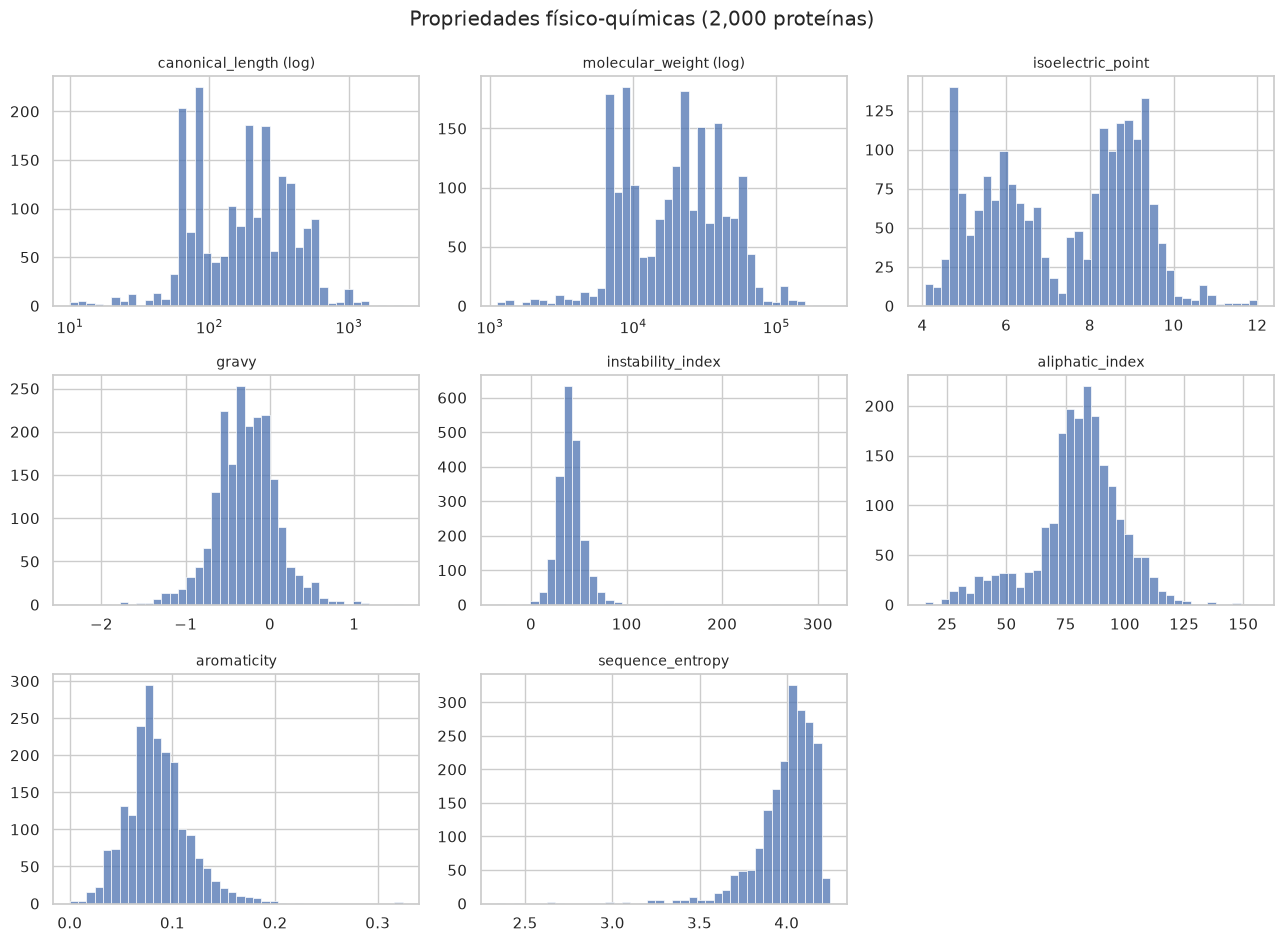

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9.5))
for ax, column in zip(axes.flat, PHYSICOCHEMICAL):
    log = column in ("canonical_length", "molecular_weight")
    sns.histplot(features_df[column], bins=40, ax=ax, log_scale=log)
    ax.set_title(column + (" (log)" if log else ""), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[len(PHYSICOCHEMICAL)].axis("off")
fig.suptitle(f"Propriedades físico-químicas ({len(features_df):,} proteínas)", y=0.99)
plt.tight_layout()
plt.show()


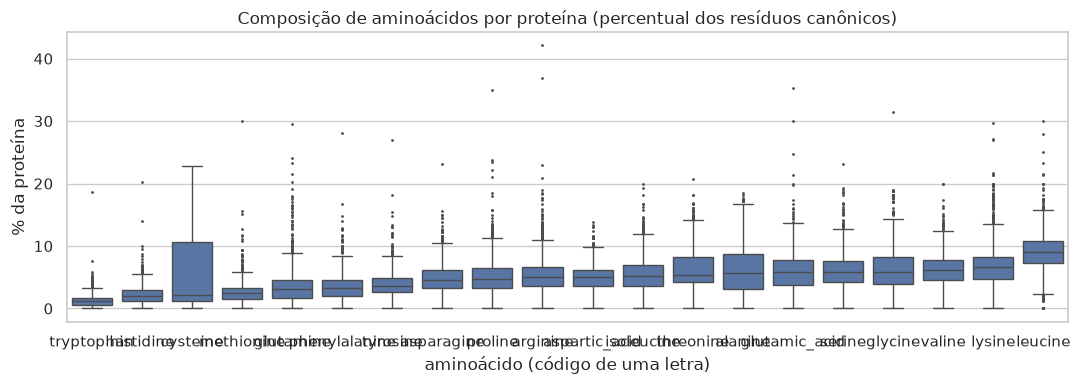

In [10]:
long_composition = composition[features.AAC_COLUMNS].melt(
    var_name="amino_acid", value_name="pct")
long_composition["amino_acid"] = long_composition["amino_acid"].str.replace(
    "_pct", "", regex=False)
order = long_composition.groupby("amino_acid")["pct"].median().sort_values().index

fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=long_composition, x="amino_acid", y="pct", order=order, ax=ax, fliersize=1)
ax.set_title("Composição de aminoácidos por proteína (percentual dos resíduos canônicos)")
ax.set_xlabel("aminoácido (código de uma letra)")
ax.set_ylabel("% da proteína")
plt.tight_layout()
plt.show()


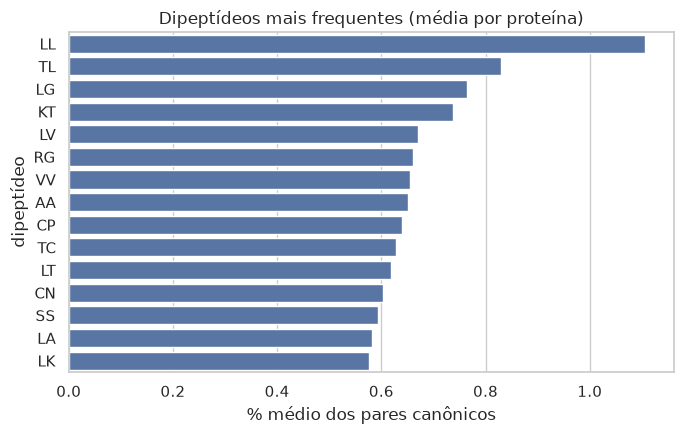

,pct_medio
L_L,1.106
T_L,0.829
L_G,0.764
K_T,0.737
L_V,0.670
R_G,0.661
V_V,0.656
A_A,0.651
C_P,0.640
T_C,0.629


In [11]:
mean_dpc = pairs[features.DPC_COLUMNS].mean().sort_values(ascending=False)
top_dpc = mean_dpc.head(15).rename(lambda name: "".join(name.split("_")))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=top_dpc.values, y=top_dpc.index, ax=ax)
ax.set_title("Dipeptídeos mais frequentes (média por proteína)")
ax.set_xlabel("% médio dos pares canônicos")
ax.set_ylabel("dipeptídeo")
plt.tight_layout()
plt.show()

display(mean_dpc.head(10).rename("pct_medio").to_frame().round(3))


## 4. Correlação e redundância

Matrizes de Pearson (relação linear) e Spearman (relação monotônica, robusta a assimetria)
entre as 35 variáveis numéricas: 8 físico-químicas, 20 percentuais de AAC e 7 classes
químicas. Redundâncias esperadas por construção:

- a AAC soma 100, então o conjunto é **linearmente dependente** (nenhum par isolado é ±1, mas
  uma coluna é combinação das outras 19);
- as classes químicas são **somas** de colunas de AAC (view `protein_features`);
- `molecular_weight` cresce com o comprimento da sequência.


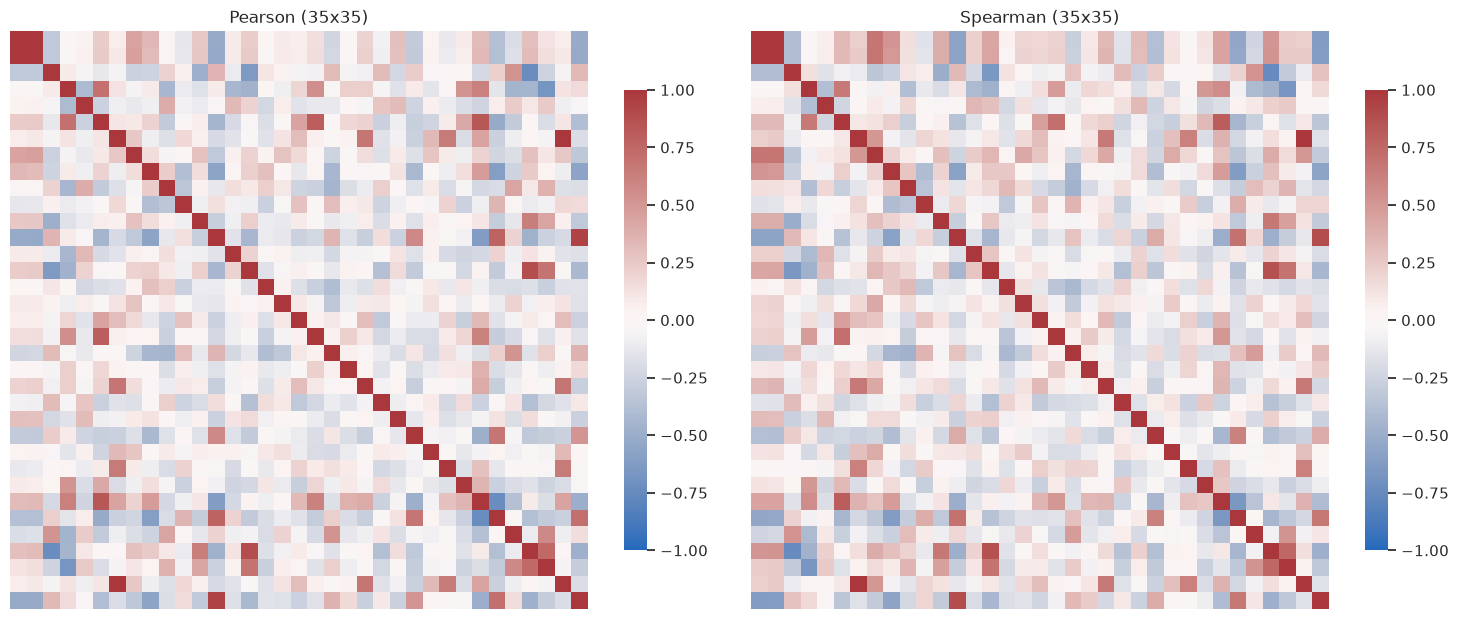

In [12]:
pearson = features_df[NUMERIC].corr("pearson")
spearman = features_df[NUMERIC].corr("spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, matrix) in zip(axes, {"Pearson": pearson, "Spearman": spearman}.items()):
    sns.heatmap(matrix, ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
                xticklabels=False, yticklabels=False, cbar_kws={"shrink": 0.75})
    ax.set_title(f"{name} ({matrix.shape[0]}x{matrix.shape[1]})")
plt.tight_layout()
plt.show()


In [13]:
def correlated_pairs(matrix: pd.DataFrame, threshold: float) -> pd.DataFrame:
    """Pares distintos com |correlação| >= threshold, do maior para o menor."""
    upper = matrix.where(np.triu(np.ones(matrix.shape, dtype=bool), k=1)).stack()
    upper = upper[upper.abs() >= threshold].sort_values(key=np.abs, ascending=False)
    return upper.rename("valor").rename_axis(["variavel_a", "variavel_b"]).reset_index()


high_pearson = correlated_pairs(pearson, 0.95)
high_spearman = correlated_pairs(spearman, 0.95)
together = high_pearson.merge(high_spearman, on=["variavel_a", "variavel_b"],
                              how="outer", suffixes=("_pearson", "_spearman"))

print(f"pares com |Pearson| >= 0,95: {len(high_pearson)}")
print(f"pares com |Spearman| >= 0,95: {len(high_spearman)}")
display(together.round(3).head(20))


pares com |Pearson| >= 0,95: 2
pares com |Spearman| >= 0,95: 2


,variavel_a,variavel_b,valor_pearson,valor_spearman
0,aromaticity,aromatic_pct,1.000,1.000
1,canonical_length,molecular_weight,0.998,0.998


## 5. Rótulos GO: frequência e prevalência

O espaço de rótulos é o GO Slim de função molecular com **41 termos** e propagação de todos os
ancestrais (`is_a`/`part_of`). Cada anotação bruta cai em exatamente um estado: `mapped`
(chegou a algum termo do vocabulário), `no_vocabulary_ancestor` (nenhum ancestral no
vocabulário), `obsolete` ou `unknown`. Os contadores por proteína vêm do export da rotulagem.

Classes raras importam para a Etapa 3: rótulos ausentes não podem ser aprendidos nesta amostra,
e rótulos com poucas dezenas de proteínas exigem cuidado na divisão treino/teste.


In [14]:
audit = labels[["n_annotations", "n_mapped", "n_no_vocabulary_ancestor",
                 "n_obsolete", "n_unknown"]].sum().rename("anotações").to_frame()
audit["pct"] = (100 * audit["anotações"] / audit.loc["n_annotations", "anotações"]).round(2)
display(audit)

prevalence = pd.DataFrame({
    "nome": pd.Series(LABEL_NAMES),
    "origem": pd.Series(LABEL_ORIGIN),
    "proteínas": Y.sum().astype(int),
    "prevalência_%": (100 * Y.mean()).round(2),
}).sort_values("proteínas", ascending=False)

absent = prevalence[prevalence["proteínas"] == 0]
rare = prevalence[(prevalence["proteínas"] > 0) & (prevalence["prevalência_%"] < 1)]
print(f"rótulos ausentes na amostra: {len(absent)} | raros (<1%): {len(rare)}")
display(prevalence.head(15))
display(prevalence.tail(12))


,anotações,pct
n_annotations,2577,100.00
n_mapped,2576,99.96
n_no_vocabulary_ancestor,1,0.04
n_obsolete,0,0.00
n_unknown,0,0.00


rótulos ausentes na amostra: 12 | raros (<1%): 11


,nome,origem,proteínas,prevalência_%
GO:0003824,catalytic activity,goslim_generic,623,31.15
GO:0005488,binding,project_extension,575,28.75
GO:0090729,toxin activity,goslim_generic,492,24.60
GO:0016787,hydrolase activity,goslim_generic,330,16.50
GO:0003677,DNA binding,goslim_generic,227,11.35
GO:0140097,"catalytic activity, acting on DNA",goslim_generic,217,10.85
GO:0016491,oxidoreductase activity,goslim_generic,146,7.30
GO:0098772,molecular function regulator activity,goslim_generic,142,7.10
GO:0016829,lyase activity,goslim_generic,131,6.55
GO:0016853,isomerase activity,goslim_generic,50,2.50


,nome,origem,proteínas,prevalência_%
GO:0003774,cytoskeletal motor activity,goslim_generic,0,0.0
GO:0009975,cyclase activity,goslim_generic,0,0.0
GO:0031386,protein tag activity,goslim_generic,0,0.0
GO:0038024,cargo receptor activity,goslim_generic,0,0.0
GO:0045182,translation regulator activity,goslim_generic,0,0.0
GO:0044183,protein folding chaperone,goslim_generic,0,0.0
GO:0048018,receptor ligand activity,goslim_generic,0,0.0
GO:0098631,cell adhesion mediator activity,goslim_generic,0,0.0
GO:0120274,virus coreceptor activity,goslim_generic,0,0.0
GO:0140104,molecular carrier activity,goslim_generic,0,0.0


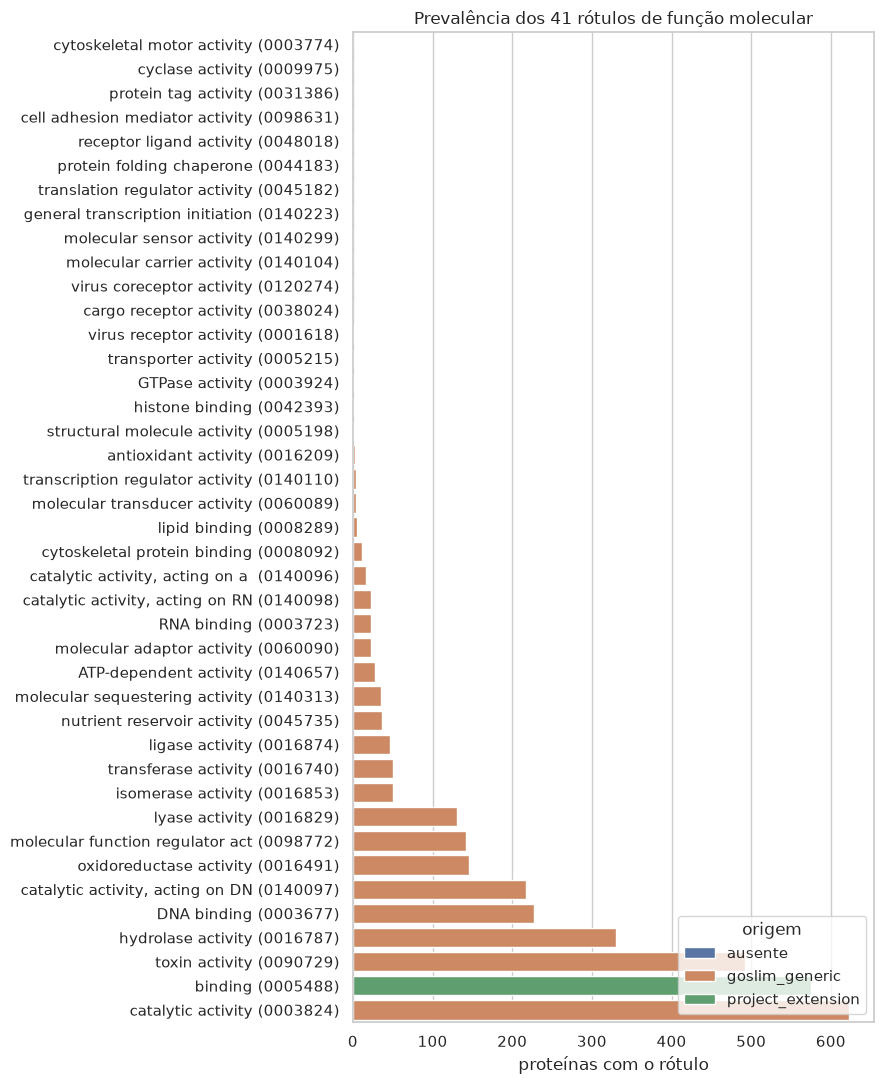

In [15]:
plot_df = prevalence.reset_index(names="go_id").assign(
    rotulo=lambda d: d["nome"].str.slice(0, 32) + " (" + d["go_id"].str.slice(3) + ")",
    origem=lambda d: np.where(d["proteínas"] > 0, d["origem"], "ausente"),
).sort_values("proteínas")

fig, ax = plt.subplots(figsize=(9, 11))
sns.barplot(data=plot_df, y="rotulo", x="proteínas", hue="origem", dodge=False, ax=ax)
ax.set_title("Prevalência dos 41 rótulos de função molecular")
ax.set_xlabel("proteínas com o rótulo")
ax.set_ylabel("")
ax.legend(loc="lower right", title="origem")
plt.tight_layout()
plt.show()


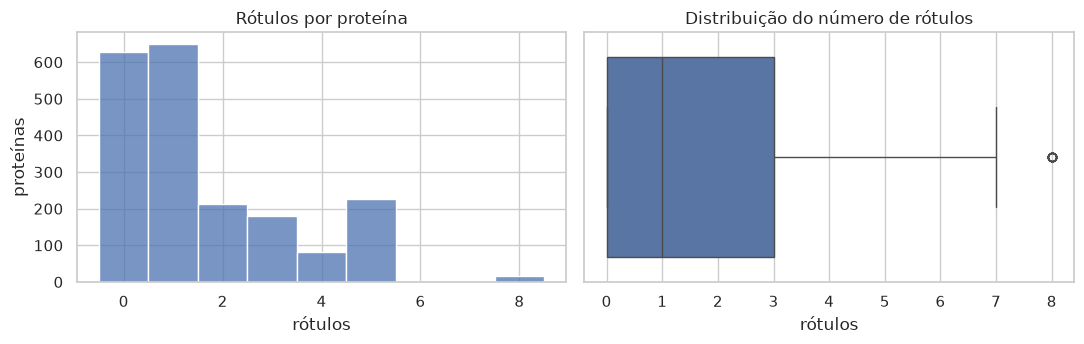

,count,mean,std,min,25%,50%,75%,max
rótulos por proteína,2000.0,1.62,1.75,0.0,0.0,1.0,3.0,8.0


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(labels["n_labels"], discrete=True, ax=axes[0])
axes[0].set_title("Rótulos por proteína")
axes[0].set_xlabel("rótulos")
axes[0].set_ylabel("proteínas")

sns.boxplot(x=labels["n_labels"], ax=axes[1])
axes[1].set_title("Distribuição do número de rótulos")
axes[1].set_xlabel("rótulos")
plt.tight_layout()
plt.show()

display(labels["n_labels"].describe().round(2).to_frame("rótulos por proteína").T)


,jaccard,phi
"(GO:0003677, GO:0140097)",0.930,0.960
"(GO:0016787, GO:0140097)",0.658,0.785
"(GO:0003677, GO:0016787)",0.638,0.762
"(GO:0003723, GO:0140098)",0.586,0.736
"(GO:0003723, GO:0140657)",0.500,0.666
"(GO:0140098, GO:0140657)",0.500,0.666
"(GO:0003824, GO:0016787)",0.530,0.661
"(GO:0003824, GO:0005488)",0.585,0.627
"(GO:0005488, GO:0016787)",0.501,0.616
"(GO:0016740, GO:0140098)",0.404,0.614


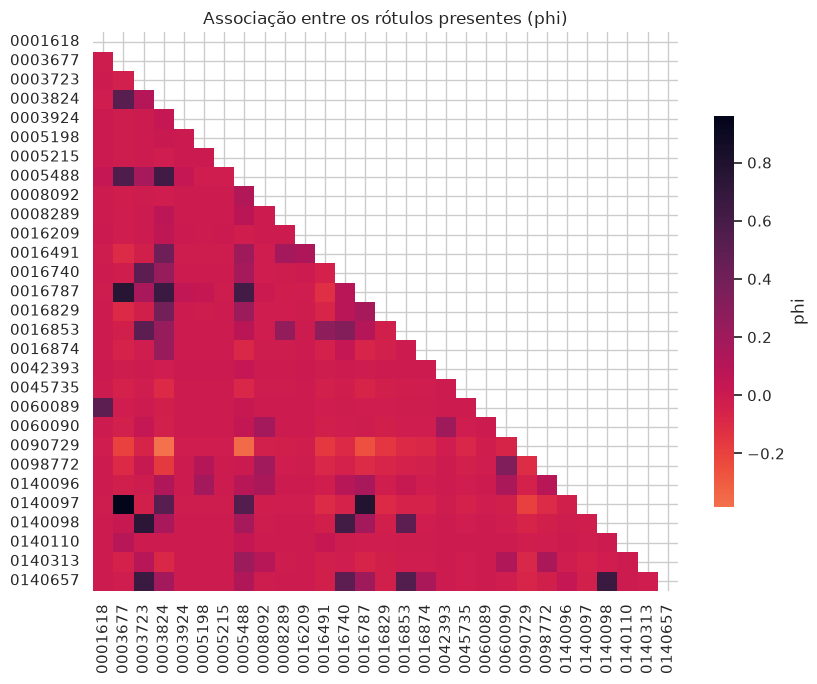

In [17]:
# Coocorrência: Jaccard (interseção/união) e phi (correlação de dois binários).
binary = Y.to_numpy(dtype=bool)
counts = binary.sum(axis=0).astype(float)
present = counts > 0
labels_present = [LABEL_IDS[i] for i in np.flatnonzero(present)]
sub = binary[:, present]
counts_present = counts[present]

intersection = sub.T.astype(int) @ sub.astype(int)
union = counts_present[:, None] + counts_present[None, :] - intersection
jaccard = np.divide(intersection, union, out=np.zeros_like(union, float), where=union > 0)

n11 = intersection.astype(float)
n10 = counts_present[:, None] - n11
n01 = counts_present[None, :] - n11
n00 = len(binary) - n11 - n10 - n01
denominator = np.sqrt((n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00))
phi = np.divide(n11 * n00 - n10 * n01, denominator,
                out=np.zeros_like(denominator, float), where=denominator > 0)

triangle = np.triu(np.ones_like(jaccard, dtype=bool), k=1)
pair_index = [(labels_present[i], labels_present[j]) for i, j in zip(*np.nonzero(triangle))]
cooccurrence = pd.DataFrame({"jaccard": jaccard[triangle], "phi": phi[triangle]},
                            index=pair_index).sort_values("phi", ascending=False)
display(cooccurrence.head(10).round(3))

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(pd.DataFrame(phi, index=labels_present, columns=labels_present), ax=ax,
            mask=np.triu(np.ones_like(phi, dtype=bool)), cmap="rocket_r", center=0,
            xticklabels=[g.replace("GO:", "") for g in labels_present],
            yticklabels=[g.replace("GO:", "") for g in labels_present],
            cbar_kws={"shrink": 0.7, "label": "phi"})
ax.set_title("Associação entre os rótulos presentes (phi)")
plt.tight_layout()
plt.show()


## 6. Associação entre atributos e rótulos

O rótulo é binário, então a medida natural é a **correlação ponto-bisserial**, que é
exatamente o Pearson entre o atributo e o indicador do rótulo. São 35 atributos × 29 rótulos
presentes = **1.015 testes**, então o p-valor precisa de correção: uso a transformação **z de
Fisher** (aproximação normal do teste t de Pearson, adequada com n = 2.000) e correção de
**Benjamini-Hochberg**.

Por que não permutação: com 1.000 permutações o menor p alcançável é 1/1.001 ≈ 1e-3, e o
limiar de BH para 1.015 testes é ≈ 5e-5 — nenhum resultado poderia ser significativo. A
permutação aparece uma célula adiante apenas como **verificação empírica do par mais forte**.

Isto é exploração, não seleção: nenhum atributo é removido e nenhum modelo é treinado.
Atributos e rótulos são alinhados explicitamente por `fasta_id` (a ordem das linhas das duas
consultas não é garantida).


In [18]:
# Alinhamento explícito: atributos e rótulos na mesma ordem de proteínas.
attributes = features_df.set_index("fasta_id").loc[Y.index, NUMERIC]
assert len(attributes) == len(Y) and attributes.notna().all().all()

X = attributes.to_numpy(dtype=float)
X = (X - X.mean(axis=0)) / X.std(axis=0)

Y_present = Y[labels_present].to_numpy(dtype=float)
Y_centered = (Y_present - Y_present.mean(axis=0)) / Y_present.std(axis=0)
observed = X.T @ Y_centered / len(Y_centered)

# p-valor pela z de Fisher: z = atanh(r) * sqrt(n - 3); p = erfc(|z| / sqrt(2)).
z_scores = np.arctanh(np.clip(observed, -0.999999, 0.999999)) * np.sqrt(len(X) - 3)
pvalues = np.frompyfunc(math.erfc, 1, 1)(np.abs(z_scores) / np.sqrt(2)).astype(float)

# Benjamini-Hochberg sobre todos os pares.
flat = pvalues.ravel()
order = np.argsort(flat)
adjusted = np.minimum.accumulate(flat[order] * len(flat) / np.arange(1, len(flat) + 1))
p_bh = np.empty_like(adjusted)
p_bh[order] = np.minimum(adjusted, 1.0)

associations = pd.DataFrame({
    "variavel": np.repeat(NUMERIC, len(labels_present)),
    "rotulo": np.tile(labels_present, len(NUMERIC)),
    "r": observed.ravel(),
    "p_fisher": flat,
    "p_bh": p_bh,
}).assign(abs_r=lambda d: d["r"].abs()).sort_values("abs_r", ascending=False)
associations["significativo"] = associations["p_bh"] < 0.05

print(f"pares testados: {len(associations):,} | com p_BH < 0,05: "
      f"{int(associations['significativo'].sum()):,} | menor p: {flat.min():.2e}")
print(f"|r| >= 0,30: {int((associations['abs_r'] >= 0.30).sum()):,} | "
      f">= 0,50: {int((associations['abs_r'] >= 0.50).sum()):,}")
display(associations.head(15).round(4).drop(columns="abs_r"))


pares testados: 1,015 | com p_BH < 0,05: 1,015 | menor p: 0.00e+00
|r| >= 0,30: 49 | >= 0,50: 6


,variavel,rotulo,r,p_fisher,p_bh,significativo
369,cysteine_pct,GO:0090729,0.8681,0.0,0.0,True
1007,sulfur_pct,GO:0090729,0.8129,0.0,0.0,True
862,polar_pct,GO:0090729,0.6930,0.0,0.0,True
717,threonine_pct,GO:0090729,0.6285,0.0,0.0,True
833,hydrophobic_pct,GO:0090729,-0.5826,0.0,0.0,True
844,polar_pct,GO:0003824,-0.5269,0.0,0.0,True
253,alanine_pct,GO:0090729,-0.4927,0.0,0.0,True
50,molecular_weight,GO:0090729,-0.4717,0.0,0.0,True
989,sulfur_pct,GO:0003824,-0.4675,0.0,0.0,True
21,canonical_length,GO:0090729,-0.4645,0.0,0.0,True


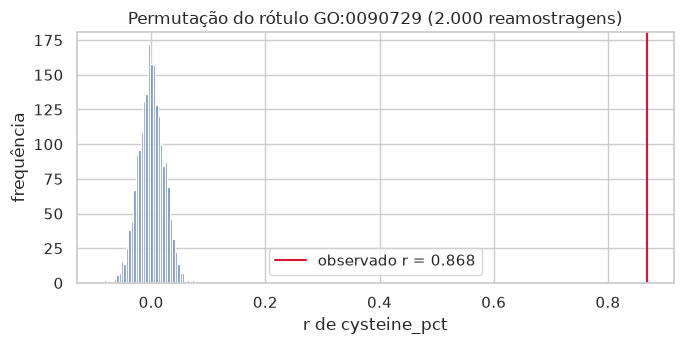

par mais forte: cysteine_pct x GO:0090729 (toxin activity)
r = 0.868 | p de Fisher = 0.00e+00 | p empírico (2000 permutações) <= 5.00e-04


In [19]:
# Verificação empírica: permutação da coluna do rótulo mais forte.
best = associations.iloc[0]
label = best["rotulo"]
y = Y[label].to_numpy(dtype=float)
y_centered = (y - y.mean()) / y.std()

rng = np.random.default_rng(0)
permuted_r = np.empty(2000)
for run in range(len(permuted_r)):
    permuted_r[run] = (X.T @ y_centered[rng.permutation(len(X))] / len(X))[
        NUMERIC.index(best["variavel"])
    ]
empirical = (np.abs(permuted_r) >= abs(best["r"])).mean()

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(permuted_r, bins=40, ax=ax)
ax.axvline(best["r"], color="crimson", label=f"observado r = {best['r']:.3f}")
ax.set_title(f"Permutação do rótulo {label} (2.000 reamostragens)")
ax.set_xlabel(f"r de {best['variavel']}")
ax.set_ylabel("frequência")
ax.legend()
plt.tight_layout()
plt.show()

print(f"par mais forte: {best['variavel']} x {label} ({LABEL_NAMES[label]})")
print(f"r = {best['r']:.3f} | p de Fisher = {best['p_fisher']:.2e} | "
      f"p empírico (2000 permutações) <= {max(empirical, 1 / 2001):.2e}")


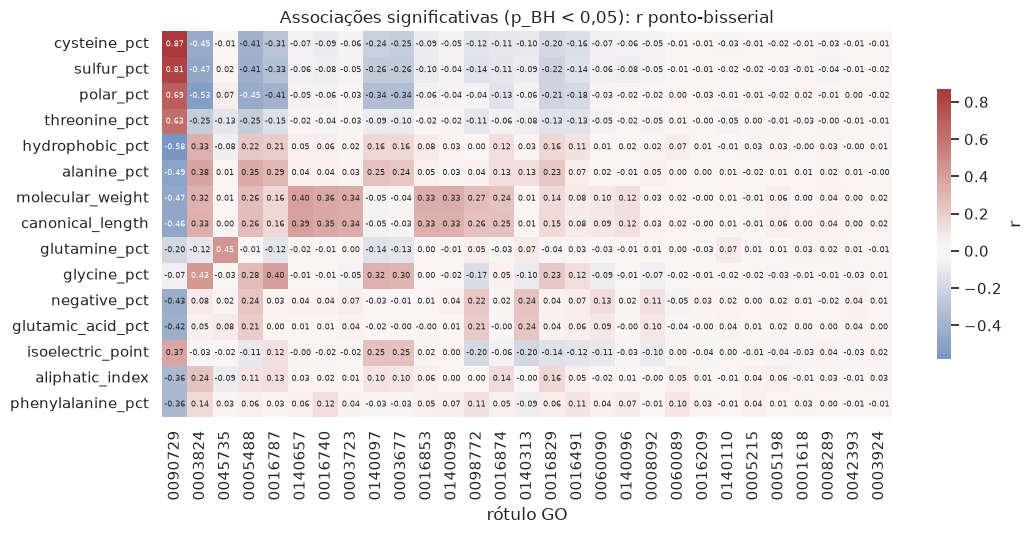

In [20]:
strong = associations[associations["significativo"]]
matrix = strong.pivot_table(index="variavel", columns="rotulo", values="r")

if matrix.empty:
    print("nenhuma associação sobreviveu à correção de Benjamini-Hochberg")
else:
    rows = matrix.abs().max(axis=1).sort_values(ascending=False).index[:15]
    columns = matrix.abs().max(axis=0).sort_values(ascending=False).index

    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.heatmap(matrix.loc[rows, columns], ax=ax, cmap="vlag", center=0,
                annot=True, fmt=".2f", annot_kws={"size": 6},
                xticklabels=[g.replace("GO:", "") for g in columns],
                cbar_kws={"shrink": 0.7, "label": "r"})
    ax.set_title("Associações significativas (p_BH < 0,05): r ponto-bisserial")
    ax.set_xlabel("rótulo GO")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()


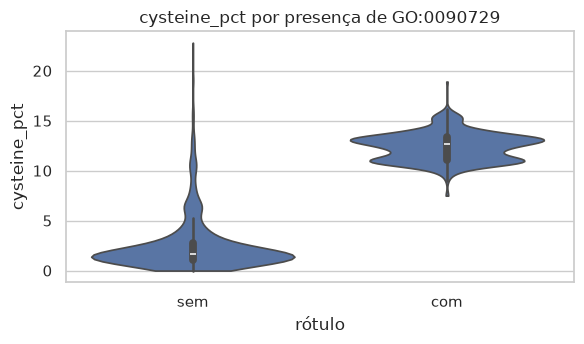

In [21]:
# O par mais forte sustenta alguma separação visível entre as classes?
plot_best = pd.DataFrame({
    "valor": attributes[best["variavel"]].to_numpy(),
    "rótulo": np.where(Y[best["rotulo"]].to_numpy() == 1, "com", "sem"),
})
fig, ax = plt.subplots(figsize=(6, 3.6))
sns.violinplot(data=plot_best, x="rótulo", y="valor", ax=ax, cut=0)
ax.set_title(f"{best['variavel']} por presença de {best['rotulo']}")
ax.set_ylabel(best["variavel"])
plt.tight_layout()
plt.show()


## 7. Conclusões

**Integridade (esta amostra de 2.000 proteínas).** As 2.000 proteínas têm linha em todas as
tabelas de features, nenhuma anotação órfã, nenhuma coluna de `protein_features` com valor
ausente e nenhuma violação de denominador ou de faixa: AAC soma 100 em todas as linhas, DPC soma
100 em todas as linhas em que é definido (e é indefinido exatamente quando não existe par
canônico), `canonical_length + noncanonical_residues == sequence_length`. As duas colunas
constantes são metadados (`source_file`, `feature_version`), não atributos.

**Distribuição.** Comprimento, massa molecular e índice de instabilidade têm cauda longa
(assimetria > 2) e dezenas a ~150 valores extremos por IQR (35 para comprimento, 95 para
instabilidade): não é erro, é a forma da distribuição. Qualquer modelo sensível a escala deve
ver logaritmo (ou padronização robusta) dessas colunas.

**Redundância.** Só dois pares passam de |r| = 0,95, mas eles são estruturais:
`aromatic_pct` ≡ `aromaticity` (r = 1,000, a classe é a soma de F+W+Y dividida pelo
comprimento) e `canonical_length` × `molecular_weight` (r = 0,998). Além disso, as 20 colunas de
AAC somam 100 (uma é combinação das outras 19) e as 7 classes químicas são somas de colunas de
AAC — redundância que um limiar de correlação par a par não detecta.

**Rótulos.** 29 dos 41 rótulos aparecem na amostra; 12 não aparecem e 11 têm menos de 1% de
prevalência. 627 proteínas (31,4%) não têm nenhum rótulo de função molecular, a maioria das
presentes tem 2 a 4 rótulos (máximo 8) e a prevalência vai de 0% a 31%. A propagação de
ancestrais mapeia 2.576 das 2.577 anotações MF (99,96%); apenas uma não tem ancestral no
vocabulário.

**Associação atributo-rótulo.** Com n = 2.000, as 1.015 combinações testadas são
estatisticamente significativas mesmo após Benjamini-Hochberg — ou seja, **significância não
discrimina nada nesta amostra**. O que ordena os pares é o tamanho de efeito: apenas 6 pares
passam de |r| = 0,50 e 49 de |r| = 0,30. Os mais fortes envolvem `toxin activity`:
`cysteine_pct` (r = 0,868), `sulfur_pct` (r = 0,813) e `polar_pct` (r = 0,693) — um padrão
consistente com a composição da amostra (492 proteínas com esse rótulo), não uma descoberta
biológica.


In [22]:
summary_table = pd.DataFrame([
    {"tema": "proteínas na base", "achado": f"{len(features_df):,}"},
    {"tema": "colunas em protein_features", "achado": f"{features_df.shape[1]}"},
    {"tema": "colunas constantes", "achado": ", ".join(constants) or "nenhuma"},
    {"tema": "colunas com ausentes", "achado": f"{int((missing > 0).sum())}"},
    {"tema": "proteínas sem rótulo MF", "achado": f"{int((Y.sum(axis=1) == 0).sum()):,}"},
    {"tema": "rótulos presentes / possíveis", "achado": f"{len(labels_present)} / 41"},
    {"tema": "rótulos ausentes", "achado": ", ".join(prevalence.index[prevalence['proteínas'] == 0])},
    {"tema": "rótulos raros (<1%)", "achado": ", ".join(rare.index) or "nenhum"},
    {"tema": "pares |Pearson| >= 0,95", "achado": f"{len(high_pearson)}"},
    {"tema": "pares |Spearman| >= 0,95", "achado": f"{len(high_spearman)}"},
    {"tema": "associações significativas (p_BH < 0,05)", "achado": f"{int(associations['significativo'].sum())}"},
    {"tema": "anotações sem ancestral no vocabulário", "achado": f"{int(audit.loc['n_no_vocabulary_ancestor', 'anotações'])}"},
])
display(summary_table)

display(high_pearson.assign(abs=lambda d: d["valor"].abs())
        .sort_values("abs", ascending=False).drop(columns="abs").head(15).round(3))


,tema,achado
0,proteínas na base,"2,000"
1,colunas em protein_features,41
2,colunas constantes,"source_file, feature_version"
3,colunas com ausentes,0
4,proteínas sem rótulo MF,627
5,rótulos presentes / possíveis,29 / 41
6,rótulos ausentes,"GO:0003774, GO:0009975, GO:0031386, GO:0038024..."
7,rótulos raros (<1%),"GO:0140096, GO:0008092, GO:0008289, GO:0060089..."
8,"pares |Pearson| >= 0,95",2
9,"pares |Spearman| >= 0,95",2


,variavel_a,variavel_b,valor
0,aromaticity,aromatic_pct,1.000
1,canonical_length,molecular_weight,0.998


In [23]:
# Os 10 pares atributo-rótulo mais fortes, para a Etapa 3 revisar.
display(associations.head(10)[["variavel", "rotulo", "r", "p_fisher", "p_bh"]].round(4))

print("Rótulos com menos de 20 proteínas (não aprendíveis nesta amostra):")
print(", ".join(f"{g} ({int(prevalence.loc[g, 'proteínas'])})"
                for g in prevalence.index[prevalence["proteínas"] < 20]) or "nenhum")


,variavel,rotulo,r,p_fisher,p_bh
369,cysteine_pct,GO:0090729,0.8681,0.0,0.0
1007,sulfur_pct,GO:0090729,0.8129,0.0,0.0
862,polar_pct,GO:0090729,0.6930,0.0,0.0
717,threonine_pct,GO:0090729,0.6285,0.0,0.0
833,hydrophobic_pct,GO:0090729,-0.5826,0.0,0.0
844,polar_pct,GO:0003824,-0.5269,0.0,0.0
253,alanine_pct,GO:0090729,-0.4927,0.0,0.0
50,molecular_weight,GO:0090729,-0.4717,0.0,0.0
989,sulfur_pct,GO:0003824,-0.4675,0.0,0.0
21,canonical_length,GO:0090729,-0.4645,0.0,0.0


Rótulos com menos de 20 proteínas (não aprendíveis nesta amostra):
GO:0140096 (16), GO:0008092 (11), GO:0008289 (5), GO:0060089 (4), GO:0140110 (4), GO:0016209 (3), GO:0005198 (2), GO:0042393 (1), GO:0005215 (1), GO:0003924 (1), GO:0001618 (1), GO:0003774 (0), GO:0009975 (0), GO:0031386 (0), GO:0038024 (0), GO:0045182 (0), GO:0044183 (0), GO:0048018 (0), GO:0098631 (0), GO:0120274 (0), GO:0140104 (0), GO:0140299 (0), GO:0140223 (0)


### Candidatos a investigar na Etapa 3 (nada foi removido nesta etapa)

| atributo / alvo | motivo | evidência |
|---|---|---|
| `aromatic_pct` | idêntico a `aromaticity` | r = 1,000 |
| `molecular_weight` | quase idêntico a `canonical_length` | r = 0,998 |
| 20 colunas de AAC | somam 100, logo 19 graus de liberdade | verificação de denominador |
| 7 classes químicas | são somas de colunas de AAC | definição da view `protein_features` |
| `source_file`, `feature_version` | metadados constantes, não atributos | `nunique() == 1` |
| 12 rótulos ausentes e 11 raros | sem massa para aprender ou validar | prevalência 0% ou < 1% |
| `canonical_length`, `molecular_weight`, `instability_index` | cauda longa (assimetria > 2) | log/padronização antes do modelo |

Decisões que ainda dependem de análise (não tomadas aqui):

- transformar (log/robusto) ou não as colunas de cauda longa, e se a transformação melhora a
  associação com os rótulos;
- agrupar rótulos raros em um alvo agregado ou declará-los fora de escopo — decisão que precisa
  do conjunto de treino, nunca do conjunto de teste externo;
- repetir todas estas medidas na base completa (575.748 proteínas) antes de fixar o conjunto de
  atributos, porque esta análise descreve 2.000 proteínas.
